# Re-ranking expression's candidates by covariance

**Question.** `beyond_expression.ipynb` showed that d_B sees within-type co-expression that expression cannot
(about 0.75 against 0.5 once cell size is removed), but only when expression is held fixed. So hold it nearly fixed
with real tiles: take a query's **50 nearest index tiles by expression** and let each distance pick its top 10 from
them. Does covariance then choose tiles that are biologically closer to the query than expression's own top 10?

**Against circularity**, the query is half A of a held-out tile's cells (a random half). Everything used for scoring
is something the query never saw:

| Score (higher = better) | What it asks |
|---|---|
| **Co-expression on held-out cells** | agreement (Pearson r over gene pairs on in both) between the within-type co-expression of half B and of each hit. Counts are size-normalised and log1p, each cell type's mean is removed, and the correlation is taken over cells. Do the hits share the query's cell states? |
| **Surroundings** | 1 − total variation between the cell-class composition of the ring of cells within 100 µm *outside* the query tile and the same ring of each hit. Does co-expression reflect the micro-environment? |
| **Own composition** (control) | 1 − TV between the cell classes of the query tile and of each hit. A re-ranking that wins only by picking more similar compositions shows up here. |

**Rankers** of the 50 candidates: Expression (its own top 10), Variance only, d_B (the method), d_B on size-normalised
counts (a variant), Correlation only; plus *Random* (the mean over all 50 candidates). All distances use each
candidate's niche blocks, as in Spindle. Tile caps 200 (production) and 400; seeds 0–4; 10 % held out.
Experiment code only; `src/` is unchanged.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

ROOT = Path.cwd().resolve()
while not (ROOT / "datasets.yaml").exists():
    ROOT = ROOT.parent
for p in (ROOT / "src", ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import paths
import spindle_dev as sd
from spindle_dev.metrics import shrink_cov, spd_to_correlation
from spindle_dev.preprocessing import build_quadtree_tiles, topvar_genes
from spindle_dev.naive import BlockVectorizer

logging.getLogger("spindle_dev").setLevel(logging.WARNING)
KEY, SEEDS, TEST_RATIO = "breast_cancer", [0, 1, 2, 3, 4], 0.1
CAPS = [200, 400]
N_CAND, TOP = 50, 10
RING = 100.0          # µm around the tile
DETECT = 0.10         # a gene is "on" in a cell set if detected in >= 10 % of its cells
MIN_GENES = 10        # co-expression agreement needs at least this many genes on in both
RANKERS = ["Expression", "Variance only", "d_B", "d_B (size-normalised)", "Correlation only"]
COLORS = {"Expression": "#EE6677", "Variance only": "#999999", "d_B": "#4477AA",
          "d_B (size-normalised)": "#66CCEE", "Correlation only": "#228833", "Random": "#BBBBBB"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Data and helpers

In [2]:
adata = sd.load_adata(paths.dataset_path(KEY))
max_genes = paths.dataset_max_genes(KEY)
genes, gene_idx = topvar_genes(adata, G=min(max_genes, adata.n_vars))
genes = np.asarray(genes).astype(str)
p = len(genes)
Xg = adata.X[:, gene_idx]
Xg = Xg.tocsr() if sp.issparse(Xg) else sp.csr_matrix(Xg)
xy = np.asarray(adata.obsm["spatial"], dtype=np.float64)
lib = np.asarray(adata.X.sum(1)).ravel()
scale = np.median(lib) / np.maximum(lib, 1)                      # per-cell size normalisation

fine_id = np.unique(adata.obs["Cluster"].astype(str).to_numpy(), return_inverse=True)[1]
CLASSES = [
    ("Invasive tumour", ["Invasive_Tumor", "Prolif_Invasive_Tumor", "T_Cell_&_Tumor_Hybrid"]),
    ("DCIS", ["DCIS_1", "DCIS_2"]),
    ("Myoepithelial", ["Myoepi_ACTA2+", "Myoepi_KRT15+"]),
    ("Stromal", ["Stromal", "Stromal_&_T_Cell_Hybrid"]),
    ("Endothelial / perivascular", ["Endothelial", "Perivascular-Like"]),
    ("Myeloid", ["Macrophages_1", "Macrophages_2", "IRF7+_DCs", "LAMP3+_DCs", "Mast_Cells"]),
    ("T cells", ["CD4+_T_Cells", "CD8+_T_Cells"]),
    ("B cells", ["B_Cells"]),
]
to_class = {t: i for i, (_, members) in enumerate(CLASSES) for t in members}
cell_cls = np.array([to_class[t] for t in adata.obs["Cluster"].astype(str)])
NC = len(CLASSES)


def cells(idx):
    return Xg[idx].toarray().astype(np.float64)


def cov_of(X):
    # as preprocessing._tile_cov: ML covariance + 1e-6 on the diagonal, shrunk once
    mu = X.mean(0)
    S = X.T @ X / X.shape[0] - np.outer(mu, mu)
    S.flat[::p + 1] += 1e-6
    return shrink_cov(S)


def coexpression(idx):
    # within-type co-expression of a cell set: size-normalised log1p counts, each type's mean removed,
    # gene-gene correlation over cells; and which genes are on
    X = cells(idx)
    Z = np.log1p(X * scale[idx, None])
    types = fine_id[idx]
    for t in np.unique(types):
        r = types == t
        Z[r] -= Z[r].mean(0)
    sd_ = Z.std(0)
    on = ((X > 0).mean(0) >= DETECT) & (sd_ > 0)
    R = np.zeros((p, p), dtype=np.float32)
    g = np.flatnonzero(on)
    if g.size >= 2:
        R[np.ix_(g, g)] = np.corrcoef(Z[:, g].T)
    return R, on


def agreement(Ra, on_a, Rb, on_b):
    g = np.flatnonzero(on_a & on_b)
    if g.size < MIN_GENES:
        return np.nan
    iu = np.triu_indices(g.size, 1)
    a, b = Ra[np.ix_(g, g)][iu], Rb[np.ix_(g, g)][iu]
    return np.corrcoef(a, b)[0, 1]


def composition(idx):
    c = np.bincount(cell_cls[idx], minlength=NC).astype(float)
    return c / max(c.sum(), 1)


def ring(tile):
    x0, y0, x1, y1 = tile.bbox
    m = (xy[:, 0] >= x0 - RING) & (xy[:, 0] <= x1 + RING) & (xy[:, 1] >= y0 - RING) & (xy[:, 1] <= y1 + RING)
    m[tile.idx] = False
    return composition(np.flatnonzero(m))


def tv_sim(a, b):
    return 1 - 0.5 * np.abs(a - b).sum(-1)

## Run

In [3]:
RES = []
for cap in CAPS:
    tiles = build_quadtree_tiles(xy, max_pts=cap, min_side=0.0, max_depth=40)
    K = len(tiles)
    X_t = [cells(t.idx) for t in tiles]
    cov_raw = [cov_of(X) for X in X_t]
    cov_nrm = [cov_of(X * scale[t.idx, None]) for X, t in zip(X_t, tiles)]
    comp = np.stack([composition(t.idx) for t in tiles])
    rings = np.stack([ring(t) for t in tiles])
    CO = [coexpression(t.idx) for t in tiles]                       # index tiles' co-expression (all cells)
    logmu = np.stack([np.log1p(X.mean(0)) for X in X_t])
    logvar = np.stack([np.log(np.diag(C)) for C in cov_raw])
    med_cells = int(np.median([t.idx.size for t in tiles]))
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        train, test = sd.split_tiles(K, seed=seed, test_ratio=TEST_RATIO)
        layout = sd.build_layout([tiles[i] for i in train],
                                 [{"tile_id": i, "cov": cov_raw[i].astype(np.float32)} for i in train],
                                 genes, adata.n_obs)
        labels = np.asarray(layout.labels).astype(int)
        VEC = {k: BlockVectorizer(layout.perm_list[k], layout.block_dict[k]) for k in sorted(set(labels.tolist()))}
        niche = dict(zip(train.tolist(), labels.tolist()))
        IV = {}                                                    # index tile -> its own-niche vectors

        def index_vec(t):
            if t not in IV:
                v = VEC[niche[t]]
                IV[t] = {"dB": v.vector(cov_raw[t]), "dBn": v.vector(cov_nrm[t]),
                         "corr": v.vector(spd_to_correlation(cov_raw[t]))}
            return IV[t]

        for q in test:
            idx = tiles[q].idx
            if idx.size < 20:
                continue
            perm = rng.permutation(idx.size)
            A, B = idx[np.sort(perm[: idx.size // 2])], idx[np.sort(perm[idx.size // 2:])]
            XA = cells(A)
            CA, CAn = cov_of(XA), cov_of(XA * scale[A, None])
            RA = spd_to_correlation(CA)
            qv = {k: {"dB": v.vector(CA), "dBn": v.vector(CAn), "corr": v.vector(RA)} for k, v in VEC.items()}
            # the 50 nearest index tiles by expression, nearest first
            d_exp = np.linalg.norm(logmu[train] - np.log1p(XA.mean(0)), axis=1)
            cand = train[np.argsort(d_exp)[:N_CAND]]
            d_var = np.linalg.norm(logvar[cand] - np.log(np.diag(CA)), axis=1)
            dist = {"Expression": np.arange(N_CAND, dtype=float), "Variance only": d_var}
            for name, key in (("d_B", "dB"), ("d_B (size-normalised)", "dBn"), ("Correlation only", "corr")):
                dist[name] = np.array([np.linalg.norm(index_vec(t)[key] - qv[niche[t]][key]) for t in cand])
            RB, onB = coexpression(B)
            co = np.array([agreement(RB, onB, *CO[t]) for t in cand])
            sur = tv_sim(rings[q], rings[cand])
            own = tv_sim(comp[q], comp[cand])
            row = {"cap": cap, "median cells": med_cells, "seed": seed, "query": q}
            for name in RANKERS + ["Random"]:
                pick = np.arange(N_CAND) if name == "Random" else np.argsort(dist[name], kind="stable")[:TOP]
                row[f"co-expression | {name}"] = np.nanmean(co[pick]) if np.isfinite(co[pick]).any() else np.nan
                row[f"surroundings | {name}"] = sur[pick].mean()
                row[f"own composition | {name}"] = own[pick].mean()
                row[f"overlap with expression top 10 | {name}"] = np.isin(pick, np.arange(TOP)).mean()
            RES.append(row)
        print(f"cap {cap} (median {med_cells} cells/tile), seed {seed}: {len(train)} index tiles, "
              f"{sum(r['cap'] == cap and r['seed'] == seed for r in RES)} queries")
RES = pd.DataFrame(RES)

[2026-10-30 15:11:03,676] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 37 low-density tile(s) (1865 spots)


/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[2026-10-30 15:11:28,544] INFO spindle_dev.layout: Leiden resolution 0.20: 4 niches, sizes [661, 489, 451, 239]


[2026-10-30 15:11:29,326] INFO spindle_dev.layout: Niche 0: 16 blocks


[2026-10-30 15:11:29,386] INFO spindle_dev.layout: Niche 1: 14 blocks


... (63 outputs left out)

[2026-10-30 15:14:13,290] INFO spindle_dev.layout: Niche 1: 15 blocks


[2026-10-30 15:14:13,346] INFO spindle_dev.layout: Niche 2: 15 blocks


[2026-10-30 15:14:13,405] INFO spindle_dev.layout: Niche 3: 16 blocks


cap 400 (median 211 cells/tile), seed 4: 702 index tiles, 78 queries


## Results

Each score as the difference from **expression's own top 10** (per query, then mean per seed). Positive = the
re-ranking picked tiles that are closer to the query on that score than expression's picks. Mean ± s.d. over the 5
seeds; *p* is a paired Wilcoxon test over all queries pooled across seeds (a query can recur across seeds, so read it
as indicative).

In [4]:
from scipy.stats import wilcoxon

SCORES = ["co-expression", "surroundings", "own composition"]
rows = []
for cap in CAPS:
    R = RES[RES.cap == cap]
    for name in RANKERS[1:] + ["Random"]:
        row = {"cap": cap, "ranker": name,
               "overlap with expr. top 10": f"{R[f'overlap with expression top 10 | {name}'].mean():.2f}"}
        for s in SCORES:
            diff = R[f"{s} | {name}"] - R[f"{s} | Expression"]
            per_seed = diff.groupby(R.seed).mean()
            ok = diff.dropna()
            pval = wilcoxon(ok).pvalue if len(ok) > 10 and (ok != 0).any() else np.nan
            row[f"Δ {s}"] = f"{per_seed.mean():+.4f} ± {per_seed.std():.4f} (p {pval:.1g})"
        rows.append(row)
    base = {s: R[f"{s} | Expression"].mean() for s in SCORES}
    print(f"cap {cap}: expression top 10 scores " + ", ".join(f"{s} {v:.3f}" for s, v in base.items()))
pd.DataFrame(rows).set_index(["cap", "ranker"])

cap 200: expression top 10 scores co-expression 0.067, surroundings 0.798, own composition 0.838
cap 400: expression top 10 scores co-expression 0.155, surroundings 0.781, own composition 0.835


overlap with expr. top 10  \
cap ranker                                            
200 Variance only                              0.49   
    d_B                                        0.43   
    d_B (size-normalised)                      0.36   
    Correlation only                           0.32   
    Random                                     0.20   
400 Variance only                              0.56   
    d_B                                        0.51   
    d_B (size-normalised)                      0.42   
    Correlation only                           0.34   
    Random                                     0.20   

                                      Δ co-expression  \
cap ranker                                              
200 Variance only          -0.0006 ± 0.0005 (p 0.004)   
    d_B                    +0.0023 ± 0.0009 (p 1e-09)   
    d_B (size-normalised)  +0.0052 ± 0.0008 (p 6e-48)   
    Correlation only       +0.0061 ± 0.0011 (p 1e-53)   
    Random                 -0.0051 ± 0.0004 (p 9e-70)   
400 Variance only            -0.0011 ± 0.0013 (p 0.2)   
    d_B                    +0.0047 ± 0.0017 (p 7e-11)   
    d_B (size-normalised)  +0.0096 ± 0.0016 (p 7e-30)   
    Correlation only       +0.0106 ± 0.0021 (p 3e-33)   
    Random                 -0.0099 ± 0.0033 (p 2e-31)   

                                       Δ surroundings  \
cap ranker                                              
200 Variance only          -0.0100 ± 0.0028 (p 1e-18)   
    d_B                    -0.0142 ± 0.0017 (p 1e-27)   
    d_B (size-normalised)  -0.0057 ± 0.0023 (p 2e-07)   
    Correlation only       -0.0187 ± 0.0019 (p 3e-33)   
    Random                 -0.0281 ± 0.0008 (p 1e-91)   
400 Variance only          -0.0095 ± 0.0019 (p 8e-08)   
    d_B                    -0.0132 ± 0.0017 (p 1e-11)   
    d_B (size-normalised)  -0.0077 ± 0.0060 (p 0.001)   
    Correlation only       -0.0180 ± 0.0020 (p 9e-11)   
    Random                 -0.0386 ± 0.0044 (p 2e-49)   

                                     Δ own composition  
cap ranker                                              
200 Variance only           -0.0192 ± 0.0017 (p 6e-73)  
    d_B                     -0.0228 ± 0.0030 (p 2e-84)  
    d_B (size-normalised)   -0.0053 ± 0.0027 (p 4e-06)  
    Correlation only        -0.0271 ± 0.0044 (p 4e-86)  
    Random                 -0.0344 ± 0.0024 (p 2e-145)  
400 Variance only           -0.0234 ± 0.0035 (p 1e-44)  
    d_B                     -0.0303 ± 0.0056 (p 6e-52)  
    d_B (size-normalised)  -0.0047 ± 0.0012 (p 0.0005)  
    Correlation only        -0.0342 ± 0.0034 (p 8e-49)  
    Random                  -0.0444 ± 0.0033 (p 1e-61)

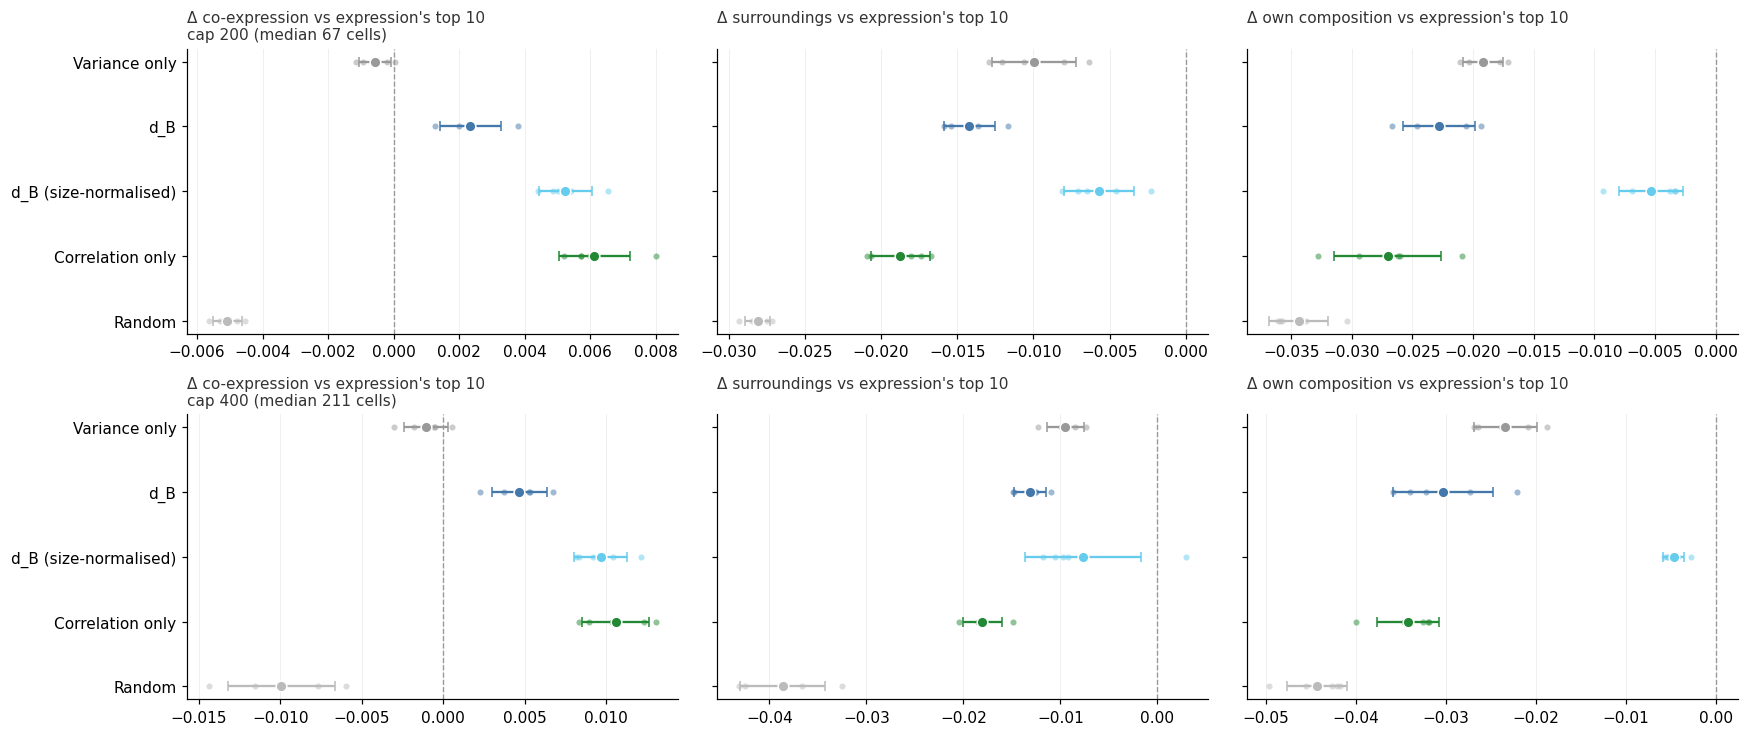

In [5]:
fig, axes = plt.subplots(len(CAPS), len(SCORES), figsize=(16, 3.4 * len(CAPS)), squeeze=False)
order = RANKERS[1:] + ["Random"]
for i, cap in enumerate(CAPS):
    R = RES[RES.cap == cap]
    for j, s in enumerate(SCORES):
        ax = axes[i, j]
        for y, name in enumerate(order):
            per_seed = (R[f"{s} | {name}"] - R[f"{s} | Expression"]).groupby(R.seed).mean()
            ax.scatter(per_seed, np.full(len(per_seed), y), s=16, color=COLORS[name], alpha=0.5, lw=0)
            ax.errorbar(per_seed.mean(), y, xerr=per_seed.std(), fmt="o", ms=7, color=COLORS[name],
                        mec="white", mew=1, capsize=3)
        ax.axvline(0, color="#999999", lw=0.9, ls="--")
        ax.set_yticks(range(len(order)), order if j == 0 else [])
        ax.invert_yaxis()
        ax.grid(axis="x", color="#eeeeee", lw=0.6)
        ax.set_axisbelow(True)
        ax.set_title(f"Δ {s} vs expression's top 10" + (f"\ncap {cap} (median {int(R['median cells'].iloc[0])} cells)"
                     if j == 0 else "\n"), color="#333333", fontsize=10, loc="left")
fig.tight_layout()
plt.show()

## Reading the results (Slurm job 24027, 30 Oct; breast, seeds 0–4)

**Co-expression: yes, real but small.** Re-ranking expression's 50 candidates by covariance picks tiles whose
within-type co-expression agrees better with the query's *held-out* cells, on every seed and at both sizes.
- Expression's own top 10 reaches r = 0.067 (cap 200) and 0.155 (cap 400); its gain over a random candidate is +0.005
  and +0.010.
- d_B adds +0.0023 and +0.0047 on top (p ≤ 1e-9): about half of what expression gains over random.
- Size-normalised d_B (+0.005, +0.010) and correlation-only (+0.006, +0.011) roughly double that.
- Variance-only adds nothing (−0.001), so the gain is co-variation, not the variances.
- The agreement itself is weak (r 0.07–0.16): per-tile co-expression is noisy, and bigger tiles help.

**Surroundings: no.** Every covariance re-ranking picks tiles whose 100 µm surroundings match the query *less* than
expression's top 10 do (d_B −0.014, correlation-only −0.019, random −0.028 to −0.039). The losses follow the losses in
own composition, so in this section co-expression does not reveal micro-environment that expression misses.

**The best trade-off is size-normalised d_B.** It keeps most of the co-expression gain and loses the least on
surroundings (−0.006 to −0.008) and composition (−0.005). The method's raw d_B spends much of its covariance on cell
size, which is why it gains less co-expression and costs more composition.

**Bottom line.** Among tiles that expression cannot separate, Spindle chooses the ones that share the query's cell
states, checked on held-out cells. The effect is statistically solid but small. It does not carry over to the tissue
context here. Size-normalising the counts before the covariance makes the co-expression part about twice as strong at
a smaller cost, but that is a change to the frozen method.
